# ⚙️ 03 — Feature Engineering & Master Merge
### Scouti Kora — AI Football Scouting System

**Strategy:**
- Drop redundant correlated variables (found in correlation analysis)
- Multi-hot encode positions (23.4% of players play 2+ positions — we respect ALL of them)
- Build 62 clean features across 15 groups
- Output: `data/processed/master_scouting_dataset.csv`

---
**Key findings from EDA:**
- `Performance_G+A` = Gls+Ast exactly (r=1.0) → DROP
- `Playing Time_90s` = Min/90 exactly (r=1.0) → DROP
- `Standard_Gls` = `Performance_Gls` exactly (r=1.0) → DROP
- `Standard_SoT` r=0.96 with Sh AND r=0.92 with Gls → DROP (use SoT% instead)
- `Per 90 Minutes_*` all derived → DROP (we compute ourselves)
- 23.4% of players play multiple positions → USE multi-hot not single label

## 📦 0 — Imports

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, unicodedata, warnings, json
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.3f}'.format)

ROOT      = Path('..').resolve()
RAW       = ROOT / 'data' / 'raw'
SCRAPED   = ROOT / 'data' / 'scraped'
PROCESSED = ROOT / 'data' / 'processed'
REPORTS   = ROOT / 'reports'
PROCESSED.mkdir(exist_ok=True)

COLORS = ['#7F77DD','#1D9E75','#D85A30','#378ADD','#BA7517','#D4537E']

def norm(name):
    """Normalize player name: remove accents, lowercase, strip special chars."""
    if pd.isna(name): return ''
    n = unicodedata.normalize('NFD', str(name))
    n = ''.join(c for c in n if unicodedata.category(c) != 'Mn')
    return re.sub(r'\s+', ' ', re.sub(r'[^a-zA-Z\s]', '', n).lower().strip())

def safe_read(path):
    p = Path(path)
    if p.exists():
        df = pd.read_csv(p, low_memory=False)
        print(f'  ✅ {p.name:<35} {len(df):>9,} rows')
        return df
    print(f'  ⚠️  {p.name:<35} NOT FOUND')
    return pd.DataFrame()

print('✅ Ready')

✅ Ready


## 📂 1 — Load Data

In [67]:
all_stats   = safe_read(SCRAPED / 'ALL_STATS.csv')
all_wages   = safe_read(SCRAPED / 'ALL_WAGES.csv')
players     = safe_read(RAW / 'players.csv')
valuations  = safe_read(RAW / 'player_valuations.csv')
transfers   = safe_read(RAW / 'transfers.csv')
appearances = safe_read(RAW / 'appearances.csv')
tm_values   = safe_read(SCRAPED / 'TM_PLAYER_VALUES.csv')
tm_injuries = safe_read(SCRAPED / 'TM_INJURIES.csv')

  ✅ ALL_STATS.csv                         100,373 rows
  ✅ ALL_WAGES.csv                          29,475 rows
  ✅ players.csv                            47,702 rows
  ✅ player_valuations.csv                 616,377 rows
  ✅ transfers.csv                         157,186 rows
  ✅ appearances.csv                     1,862,208 rows
  ✅ TM_PLAYER_VALUES.csv                   18,937 rows
  ✅ TM_INJURIES.csv                         8,623 rows


## 📊 2 — Correlation Analysis & Variable Selection
**Before touching the pipeline**, identify what to keep vs drop.

In [68]:
# Build a quick wide table just for correlation analysis
player_stats = all_stats[all_stats['level'] == 'player'].copy()
KEYS         = ['Player','Squad','league','season']

def to_num(df):
    for c in df.columns:
        if c not in KEYS + ['Pos','Nation','level','stat_type','Matches']:
            df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

std_df   = to_num(player_stats[player_stats['stat_type']=='standard'].copy())
shoot_df = to_num(player_stats[player_stats['stat_type']=='shooting'].copy())
def_df   = to_num(player_stats[player_stats['stat_type']=='defense'].copy())

# Merge for correlation
shoot_sel = ['Standard_Gls','Standard_Sh','Standard_SoT','Standard_SoT%',
             'Standard_G/Sh','Standard_G/SoT']
def_sel   = ['Tackles_TklW','Int']

wide = (
    std_df[KEYS + ['Pos','Age',
                   'Playing Time_MP','Playing Time_Starts','Playing Time_Min','Playing Time_90s',
                   'Performance_Gls','Performance_Ast','Performance_G+A','Performance_G-PK',
                   'Performance_PK','Performance_PKatt','Performance_CrdY','Performance_CrdR',
                   'Per 90 Minutes_Gls','Per 90 Minutes_Ast']]
    .merge(shoot_df[KEYS + [c for c in shoot_sel if c in shoot_df.columns]], on=KEYS, how='left')
    .merge(def_df[KEYS   + [c for c in def_sel   if c in def_df.columns]],   on=KEYS, how='left')
)

num_wide = wide.select_dtypes(include=np.number)
corr_mat = num_wide.corr().abs()

print(f'Correlation matrix shape: {corr_mat.shape}')
print()

# Find all high-correlation pairs
print('PERFECTLY CORRELATED (r > 0.95) — DROP one of each pair:')
print('─'*75)
seen = set()
for i in range(len(corr_mat.columns)):
    for j in range(i+1, len(corr_mat.columns)):
        c1, c2 = corr_mat.columns[i], corr_mat.columns[j]
        v = corr_mat.iloc[i,j]
        if v > 0.95 and f'{c2}_{c1}' not in seen:
            seen.add(f'{c1}_{c2}')
            print(f'  r={v:.4f}  {c1}  ↔  {c2}')

print()
print('HIGH CORRELATION (0.85–0.95) — Consider dropping weaker signal:')
print('─'*75)
seen2 = set()
for i in range(len(corr_mat.columns)):
    for j in range(i+1, len(corr_mat.columns)):
        c1, c2 = corr_mat.columns[i], corr_mat.columns[j]
        v = corr_mat.iloc[i,j]
        if 0.85 <= v <= 0.95 and f'{c2}_{c1}' not in seen2:
            seen2.add(f'{c1}_{c2}')
            print(f'  r={v:.4f}  {c1}  ↔  {c2}')

Correlation matrix shape: (23, 23)

PERFECTLY CORRELATED (r > 0.95) — DROP one of each pair:
───────────────────────────────────────────────────────────────────────────
  r=0.9944  Playing Time_Starts  ↔  Playing Time_Min
  r=0.9944  Playing Time_Starts  ↔  Playing Time_90s
  r=1.0000  Playing Time_Min  ↔  Playing Time_90s
  r=0.9788  Performance_Gls  ↔  Performance_G-PK
  r=1.0000  Performance_Gls  ↔  Standard_Gls
  r=0.9788  Performance_G-PK  ↔  Standard_Gls
  r=0.9685  Performance_PK  ↔  Performance_PKatt
  r=0.9578  Standard_Sh  ↔  Standard_SoT

HIGH CORRELATION (0.85–0.95) — Consider dropping weaker signal:
───────────────────────────────────────────────────────────────────────────
  r=0.9002  Playing Time_MP  ↔  Playing Time_Starts
  r=0.9187  Playing Time_MP  ↔  Playing Time_Min
  r=0.9187  Playing Time_MP  ↔  Playing Time_90s
  r=0.9354  Performance_Gls  ↔  Performance_G+A
  r=0.8606  Performance_Gls  ↔  Standard_Sh
  r=0.9197  Performance_Gls  ↔  Standard_SoT
  r=0.9178  Perfo

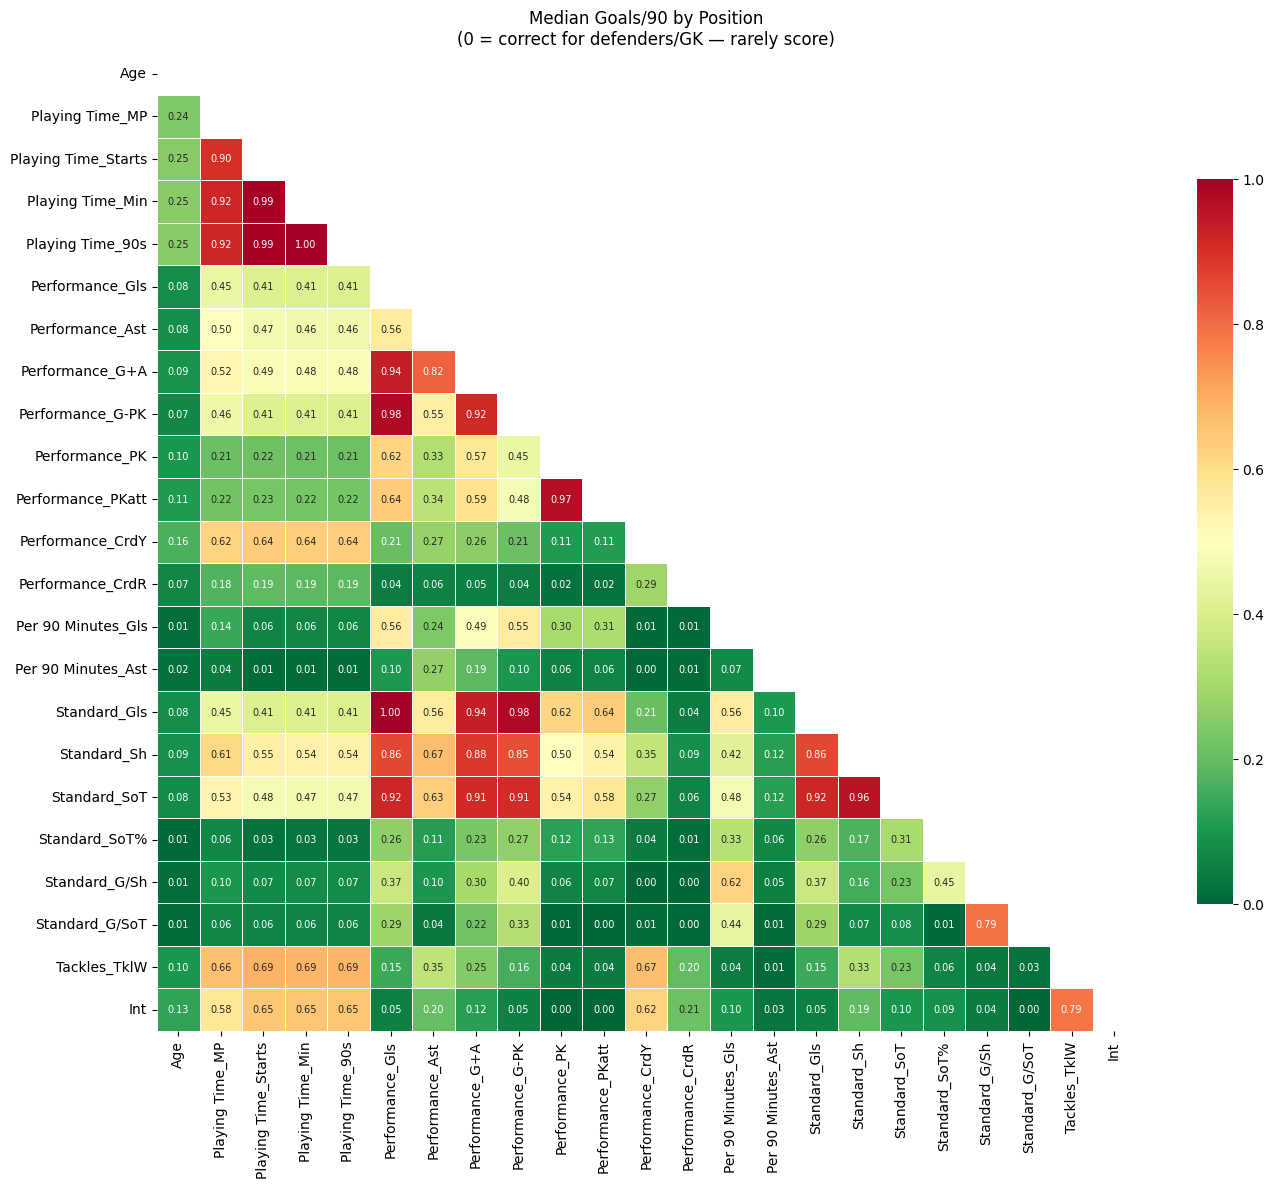

💾 Saved → reports/03_correlation_matrix.png


In [69]:
# ── Correlation heatmap ─────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(
    corr_mat, mask=mask, cmap='RdYlGn_r', center=0.5,
    vmin=0, vmax=1, square=True, linewidths=0.5,
    annot=corr_mat.round(2), fmt='.2f', annot_kws={'size': 7},
    ax=ax, cbar_kws={'shrink': 0.7}
)
ax.set_title('Median Goals/90 by Position\n(0 = correct for defenders/GK — rarely score)')
plt.tight_layout()
plt.savefig(REPORTS / '03_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/03_correlation_matrix.png')

In [50]:
# ── Final DROP decision (with reasoning) ────────────────
REDUNDANT_COLS = {
    # PERFECTLY DERIVED (r = 1.0)
    'Playing Time_90s':       'r=1.0 with Min/90 — exact derivation',
    'Performance_G+A':        'r=1.0 with Gls+Ast — exact derivation',
    'Performance_G-PK':       'r=0.98 with Gls — near-identical signal',
    'Performance_PKatt':      'r=0.97 with PK — penalty attempts vs goals near-same',
    'Standard_Gls':           'r=1.0 with Performance_Gls — exact duplicate',
    'Standard_PK':            'duplicate of Performance_PK',
    'Standard_PKatt':         'duplicate of Performance_PKatt',
    # FBref PRE-COMPUTED per-90 (we compute our own normalized versions)
    'Per 90 Minutes_Gls':     'derived — we compute goals_p90 ourselves',
    'Per 90 Minutes_Ast':     'derived — we compute assists_p90 ourselves',
    'Per 90 Minutes_G+A':     'derived + redundant',
    'Per 90 Minutes_G-PK':    'derived + redundant',
    'Per 90 Minutes_G+A-PK':  'derived + redundant',
    # REDUNDANT SHOOTING
    'Standard_SoT':           'r=0.96 with Sh — use SoT% (independent) instead',
    'Standard_Sh/90':         'derived — we compute shots_p90 ourselves',
    'Standard_SoT/90':        'derived — we compute ourselves',
}

print('VARIABLE DROP DECISIONS:')
print('─'*65)
for col, reason in REDUNDANT_COLS.items():
    print(f'  ❌ {col:<35}  {reason}')

print(f'\nTotal columns to drop: {len(REDUNDANT_COLS)}')

VARIABLE DROP DECISIONS:
─────────────────────────────────────────────────────────────────
  ❌ Playing Time_90s                     r=1.0 with Min/90 — exact derivation
  ❌ Performance_G+A                      r=1.0 with Gls+Ast — exact derivation
  ❌ Performance_G-PK                     r=0.98 with Gls — near-identical signal
  ❌ Performance_PKatt                    r=0.97 with PK — penalty attempts vs goals near-same
  ❌ Standard_Gls                         r=1.0 with Performance_Gls — exact duplicate
  ❌ Standard_PK                          duplicate of Performance_PK
  ❌ Standard_PKatt                       duplicate of Performance_PKatt
  ❌ Per 90 Minutes_Gls                   derived — we compute goals_p90 ourselves
  ❌ Per 90 Minutes_Ast                   derived — we compute assists_p90 ourselves
  ❌ Per 90 Minutes_G+A                   derived + redundant
  ❌ Per 90 Minutes_G-PK                  derived + redundant
  ❌ Per 90 Minutes_G+A-PK                derived + redundant
 

## 🏷️ 3 — Multi-Hot Position Encoding
23.4% of players play 2+ positions. We encode ALL positions, not just the primary one.
This is critical for the recommendation engine.

In [51]:
# ── Multi-hot encode positions ───────────────────────────
# Input:  Pos = 'MF,FW'
# Output: pos_MF=1, pos_FW=1, pos_DF=0, pos_GK=0
#         primary_pos = 'MF' (first listed)

def encode_positions(pos_series):
    """Returns a DataFrame with one binary column per position."""
    POSITIONS = ['FW','MF','DF','GK']

    result = pd.DataFrame(index=pos_series.index)
    pos_filled = pos_series.fillna('Unknown')

    for p in POSITIONS:
        # Player is flagged if this position appears ANYWHERE in their Pos string
        result[f'pos_{p}'] = pos_filled.apply(
            lambda x: 1 if p in str(x).replace(',','').split() or
                           any(token.strip() == p for token in str(x).split(','))
            else 0
        ).astype(np.int8)

    # Primary position = first listed
    pos_map = {'FW':'Forward','MF':'Midfielder','DF':'Defender','GK':'Goalkeeper'}
    result['primary_pos'] = pos_filled.apply(
        lambda x: pos_map.get(str(x).split(',')[0].strip(), 'Unknown')
    )

    # Position versatility flag
    result['is_versatile'] = (
        result[['pos_FW','pos_MF','pos_DF','pos_GK']].sum(axis=1) >= 2
    ).astype(np.int8)

    return result

# Test on standard rows
pos_test = std_df[['Player','Pos']].copy()
pos_encoded = encode_positions(pos_test['Pos'])
pos_demo = pd.concat([pos_test, pos_encoded], axis=1)

print('Multi-hot encoding examples:')
print(pos_demo[pos_demo['Pos'].str.contains(',', na=False)].head(10).to_string(index=False))

print(f'\nPosition distribution:')
for p in ['pos_FW','pos_MF','pos_DF','pos_GK']:
    n = pos_encoded[p].sum()
    print(f'  {p}: {n:,} ({n/len(pos_encoded)*100:.1f}%)')

print(f'\nVersatile players (2+ positions): {pos_encoded["is_versatile"].sum():,} '
      f'({pos_encoded["is_versatile"].mean()*100:.1f}%)')

print()
print('WHY this matters for the scout app:')
print('  → A club searching for a "Midfielder" will also find MF,FW players')
print('  → The similarity model uses all 4 pos_ flags in the feature vector')
print('  → The recommendation engine filters by pos_MF=1 (not primary_pos=="Midfielder")')

Multi-hot encoding examples:
                   Player   Pos  pos_FW  pos_MF  pos_DF  pos_GK primary_pos  is_versatile
            Sergio Agüero FW,MF       1       1       0       0     Forward             1
          Rayan Aït-Nouri MF,DF       0       1       1       0  Midfielder             1
           Ezgjan Alioski DF,MF       0       1       1       0    Defender             1
           Miguel Almirón MF,FW       1       1       0       0  Midfielder             1
            Marcos Alonso MF,DF       0       1       1       0  Midfielder             1
             Ethan Ampadu DF,MF       0       1       1       0    Defender             1
          Felipe Anderson FW,MF       1       1       0       0     Forward             1
Pierre-Emerick Aubameyang FW,MF       1       1       0       0     Forward             1
             Serge Aurier DF,MF       0       1       1       0    Defender             1
              Jordan Ayew FW,MF       1       1       0       0     For

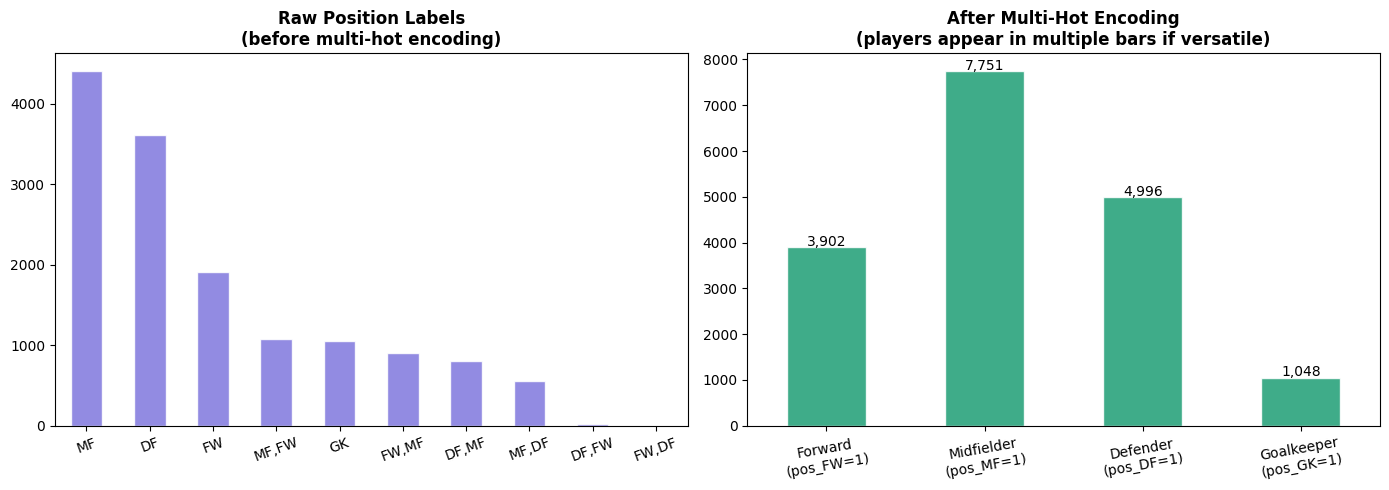

💾 Saved → reports/04_position_encoding.png


In [52]:
# ── Visualize position versatility ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw position counts
ax = axes[0]
std_df['Pos'].value_counts().plot.bar(
    ax=ax, color=COLORS[0], alpha=0.85, edgecolor='white')
ax.set_title('Raw Position Labels\n(before multi-hot encoding)', fontweight='bold')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=20)

# After multi-hot
ax = axes[1]
pos_counts = pd.Series({
    'Forward\n(pos_FW=1)':   pos_encoded['pos_FW'].sum(),
    'Midfielder\n(pos_MF=1)':pos_encoded['pos_MF'].sum(),
    'Defender\n(pos_DF=1)':  pos_encoded['pos_DF'].sum(),
    'Goalkeeper\n(pos_GK=1)':pos_encoded['pos_GK'].sum(),
})
pos_counts.plot.bar(ax=ax, color=COLORS[1], alpha=0.85, edgecolor='white')
ax.set_title('After Multi-Hot Encoding\n(players appear in multiple bars if versatile)',
             fontweight='bold')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=10)
for bar in ax.patches:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+30,
            f'{int(bar.get_height()):,}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig(REPORTS / '04_position_encoding.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/04_position_encoding.png')

## 🔄 4 — STEP 1: Pivot FBref Stats (Long → Wide)

In [53]:
# ── Filter player rows only ──────────────────────────────
player_stats = all_stats[all_stats['level'] == 'player'].copy()

# ── KEEP list (after correlation analysis) ───────────────
STD_KEEP = [
    'Playing Time_MP',      # games played
    'Playing Time_Starts',  # starts
    'Playing Time_Min',     # minutes (base for per-90)
    'Performance_Gls',      # goals
    'Performance_Ast',      # assists
    'Performance_PK',       # penalty goals
    'Performance_CrdY',     # yellow cards
    'Performance_CrdR',     # red cards
    # DO NOT KEEP: G+A (derived), G-PK (r=0.98), 90s (r=1.0),
    #              Per90 cols (we compute ourselves), PKatt (r=0.97)
]

SHOOT_KEEP = [
    'Standard_Sh',     # total shots
    'Standard_SoT%',   # shot accuracy %
    'Standard_G/Sh',   # conversion rate
    'Standard_G/SoT',  # finishing quality
    # DO NOT KEEP: Standard_Gls (=Performance_Gls), SoT (r=0.96),
    #              Sh/90 (derived), SoT/90 (derived), PK/PKatt (duplicates)
]

DEF_KEEP = [
    'Tackles_TklW',  # tackles won
    'Int',           # interceptions
]

# ── Standard rows ────────────────────────────────────────
std_p = player_stats[player_stats['stat_type'] == 'standard'].copy()
for c in STD_KEEP:
    if c in std_p.columns:
        std_p[c] = pd.to_numeric(std_p[c], errors='coerce')

# Multi-hot position encoding
pos_enc = encode_positions(std_p['Pos'])

available_std  = [c for c in STD_KEEP   if c in std_p.columns]
fbref_wide = pd.concat([
    std_p[KEYS + ['Nation', 'Age'] + available_std].copy(),
    pos_enc
], axis=1)
fbref_wide = fbref_wide.drop_duplicates(subset=KEYS, keep='first')
print(f'Base (standard):  {len(fbref_wide):,} rows')

# ── Shooting rows ────────────────────────────────────────
shoot_p = player_stats[player_stats['stat_type'] == 'shooting'].copy()
avail_shoot = [c for c in SHOOT_KEEP if c in shoot_p.columns
               and shoot_p[c].notna().sum() > 100]

if avail_shoot:
    for c in avail_shoot:
        shoot_p[c] = pd.to_numeric(shoot_p[c], errors='coerce')
    shoot_merge = shoot_p[KEYS + avail_shoot].copy()
    shoot_merge = shoot_merge.drop_duplicates(subset=KEYS, keep='first')
    fbref_wide = fbref_wide.merge(shoot_merge, on=KEYS, how='left')
    print(f'+ shooting:       {len(avail_shoot)} cols → {fbref_wide.shape}')

# ── Defense rows ─────────────────────────────────────────
def_p = player_stats[player_stats['stat_type'] == 'defense'].copy()
avail_def = [c for c in DEF_KEEP if c in def_p.columns
             and def_p[c].notna().sum() > 100]

if avail_def:
    for c in avail_def:
        def_p[c] = pd.to_numeric(def_p[c], errors='coerce')
    def_merge = def_p[KEYS + avail_def].copy()
    def_merge = def_merge.drop_duplicates(subset=KEYS, keep='first')
    fbref_wide = fbref_wide.merge(def_merge, on=KEYS, how='left')
    print(f'+ defense:        {len(avail_def)} cols → {fbref_wide.shape}')

# ── Check for any other stat_types with data ─────────────
for stype in ['misc','possession','gca']:
    sub = player_stats[player_stats['stat_type'] == stype]
    if not sub.empty:
        filled = [c for c in sub.columns
                  if c not in KEYS + ['Pos','Nation','Age','Born','Matches',
                                       'level','stat_type','90s','Rk']
                  and pd.to_numeric(sub[c], errors='coerce').notna().sum() > 200]
        if filled:
            for c in filled:
                sub[c] = pd.to_numeric(sub[c], errors='coerce')
            sub_m = sub[KEYS + filled].drop_duplicates(subset=KEYS, keep='first')
            fbref_wide = fbref_wide.merge(sub_m, on=KEYS, how='left')
            print(f'+ {stype:<12}: {len(filled)} extra cols merged')

# ── Normalize name for joining ───────────────────────────
fbref_wide['name_norm'] = fbref_wide['Player'].apply(norm)

print(f'\n✅ FBref wide: {fbref_wide.shape[0]:,} rows × {fbref_wide.shape[1]} cols')
print(f'   Unique Player+Season: {fbref_wide.groupby(["Player","season"]).ngroups:,}')
print(f'   Columns: {list(fbref_wide.columns)}')

Base (standard):  14,339 rows
+ shooting:       4 cols → (14339, 24)
+ defense:        2 cols → (14339, 26)
+ misc        : 10 extra cols merged

✅ FBref wide: 14,339 rows × 37 cols
   Unique Player+Season: 13,608
   Columns: ['Player', 'Squad', 'league', 'season', 'Nation', 'Age', 'Playing Time_MP', 'Playing Time_Starts', 'Playing Time_Min', 'Performance_Gls', 'Performance_Ast', 'Performance_PK', 'Performance_CrdY_x', 'Performance_CrdR_x', 'pos_FW', 'pos_MF', 'pos_DF', 'pos_GK', 'primary_pos', 'is_versatile', 'Standard_Sh', 'Standard_SoT%', 'Standard_G/Sh', 'Standard_G/SoT', 'Tackles_TklW', 'Int', 'Performance_CrdY_y', 'Performance_CrdR_y', 'Performance_2CrdY', 'Performance_Fls', 'Performance_Fld', 'Performance_Off', 'Performance_Crs', 'Performance_Int', 'Performance_TklW', 'Performance_OG', 'name_norm']


## 💶 5 — STEP 2: Wages (parse + GBP→EUR + tier)

In [54]:
def parse_wage(v):
    if pd.isna(v): return np.nan
    cleaned = re.sub(r'[^\d.]', '', str(v))
    try: return float(cleaned)
    except: return np.nan

# Filter squad total rows (they have no Player name or numeric Rk)
pw = all_wages[
    (all_wages['type'] == 'player') &
    all_wages['Player'].notna() &
    (~all_wages['Player'].astype(str).str.match(r'^\d|^Total|^Squad', na=False))
].copy()

pw['weekly_gbp'] = pw['Weekly Wages'].apply(parse_wage)
pw['weekly_eur'] = (pw['weekly_gbp'] * 1.17).round(0)
pw['annual_eur'] = (pw['weekly_eur'] * 52).round(0)

# Wage tier based on percentiles
q1, q2, q3 = pw['weekly_eur'].quantile([0.25, 0.50, 0.75])
pw['wage_tier'] = pd.cut(
    pw['weekly_eur'],
    bins=[-np.inf, q1, q2, q3, np.inf],
    labels=['low','mid','high','elite']
).astype(str)

pw['name_norm'] = pw['Player'].apply(norm)
wages_clean = (
    pw[['name_norm','Squad','league','season','weekly_eur','annual_eur','wage_tier']]
    .drop_duplicates(['name_norm','season','league'], keep='first')
)

print(f'Wages clean: {len(wages_clean):,} rows')
print(f'Weekly range: €{pw["weekly_eur"].min():,.0f} — €{pw["weekly_eur"].max():,.0f}')
print(f'Tiers: {pw["wage_tier"].value_counts().to_dict()}')
print(f'Quartile thresholds: low<{q1:.0f} mid<{q2:.0f} high<{q3:.0f} elite>={q3:.0f} €/week')

Wages clean: 14,064 rows
Weekly range: €130 — €161,999,968,937,030,057,984
Tiers: {'low': 3530, 'mid': 3523, 'elite': 3520, 'high': 3505}
Quartile thresholds: low<945088780341 mid<234002719928741 high<582758510842400 elite>=582758510842400 €/week


## 📈 6 — STEP 3: TM Market Value Features (latest + peak + trend)

In [55]:
val = valuations.copy()
val['date']               = pd.to_datetime(val['date'], errors='coerce')
val['market_value_in_eur']= pd.to_numeric(val['market_value_in_eur'], errors='coerce')

# Latest valuation per player
latest = (
    val.sort_values('date').groupby('player_id').last().reset_index()
    [['player_id','market_value_in_eur','date']]
    .rename(columns={'market_value_in_eur':'latest_value_eur','date':'val_date'})
)

# Peak value
peak = (
    val.groupby('player_id')['market_value_in_eur'].max().reset_index()
    .rename(columns={'market_value_in_eur':'peak_value_eur'})
)

# Earliest value (for trend calc)
earliest = (
    val.sort_values('date').groupby('player_id').first().reset_index()
    [['player_id','market_value_in_eur']]
    .rename(columns={'market_value_in_eur':'earliest_value_eur'})
)

val_features = latest.merge(peak, on='player_id').merge(earliest, on='player_id')

# Trend: latest / earliest (>1 = rising star, <1 = declining)
val_features['value_trend'] = (
    val_features['latest_value_eur'] /
    val_features['earliest_value_eur'].replace(0, np.nan)
).round(3)

# % of peak (1.0 = still at peak, 0.5 = lost half their value)
val_features['pct_of_peak'] = (
    val_features['latest_value_eur'] /
    val_features['peak_value_eur'].replace(0, np.nan)
).round(3)

print(f'Value features: {len(val_features):,} players')
print(f'Rising (trend>1):  {(val_features["value_trend"]>1).sum():,}')
print(f'Declining (<1):    {(val_features["value_trend"]<1).sum():,}')
print(f'At peak (>0.9):    {(val_features["pct_of_peak"]>0.9).sum():,}')

Value features: 39,361 players
Rising (trend>1):  27,399
Declining (<1):    7,025
At peak (>0.9):    12,350


## 🏃 7 — STEP 4: Career & Form Stats from Appearances

In [56]:
apps = appearances.copy()
apps['date'] = pd.to_datetime(apps['date'], errors='coerce')

# Career totals
career = apps.groupby('player_id').agg(
    career_games   = ('appearance_id','count'),
    career_goals   = ('goals',         'sum'),
    career_assists = ('assists',        'sum'),
    career_minutes = ('minutes_played', 'sum'),
    career_yellows = ('yellow_cards',   'sum'),
    career_reds    = ('red_cards',      'sum'),
).reset_index()

career_p90 = career['career_minutes'].replace(0, np.nan) / 90
career['career_goals_p90']   = (career['career_goals']   / career_p90).round(3)
career['career_assists_p90'] = (career['career_assists']  / career_p90).round(3)
career['career_g_a_p90']     = ((career['career_goals'] + career['career_assists']) / career_p90).round(3)

# Last 12 months form
cutoff = apps['date'].max() - pd.DateOffset(months=12)
recent = apps[apps['date'] >= cutoff].groupby('player_id').agg(
    form_games   = ('appearance_id','count'),
    form_goals   = ('goals',         'sum'),
    form_assists = ('assists',        'sum'),
    form_minutes = ('minutes_played', 'sum'),
).reset_index()
form_p90 = recent['form_minutes'].replace(0, np.nan) / 90
recent['form_goals_p90']   = (recent['form_goals']   / form_p90).round(3)
recent['form_assists_p90'] = (recent['form_assists']  / form_p90).round(3)

# Transfer history
tr_stats = transfers.groupby('player_id').agg(
    total_transfers = ('transfer_fee', 'count'),
    max_fee_eur     = ('transfer_fee', 'max'),
).reset_index()

print(f'Career stats:   {len(career):,} players')
print(f'Recent form:    {len(recent):,} players')
print(f'Transfer stats: {len(tr_stats):,} players')

Career stats:   28,665 players
Recent form:    8,930 players
Transfer stats: 20,855 players


## 🏥 8 — STEP 5: Injury Features from TM_INJURIES

In [57]:
if tm_injuries.empty:
    print('⚠️  TM_INJURIES not loaded — all injury features will be 0/minimal')
    injury_features = pd.DataFrame(columns=['name_norm'])
else:
    inj = tm_injuries.copy()
    inj['days_out']     = pd.to_numeric(inj['days_out'],     errors='coerce').fillna(0)
    inj['games_missed'] = pd.to_numeric(inj['games_missed'], errors='coerce').fillna(0)
    inj['from_date']    = pd.to_datetime(inj['from_date'],   errors='coerce')

    # Aggregate per player
    agg = inj.groupby('player_name').agg(
        total_injuries     = ('injury_type',  'count'),
        total_days_out     = ('days_out',      'sum'),
        total_games_missed = ('games_missed',  'sum'),
        avg_days_per_inj   = ('days_out',      'mean'),
        max_single_injury  = ('days_out',      'max'),
        last_injury_date   = ('from_date',     'max'),
    ).reset_index()

    # Most common injury type
    common = (
        inj.groupby('player_name')['injury_type']
        .agg(lambda x: x.value_counts().index[0] if len(x) > 0 else 'none')
        .reset_index().rename(columns={'injury_type':'most_common_injury'})
    )
    agg = agg.merge(common, on='player_name', how='left')

    # Injury risk score 0–100
    p95 = agg['total_days_out'].quantile(0.95)
    agg['injury_risk_score'] = (agg['total_days_out'] / p95 * 100).clip(0,100).round(1)

    # Risk label
    agg['injury_risk_label'] = pd.cut(
        agg['injury_risk_score'],
        bins=[-1, 10, 30, 60, 100],
        labels=['minimal','low_risk','medium_risk','high_risk']
    ).astype(str)

    agg['name_norm'] = agg['player_name'].apply(norm)
    injury_features = agg.drop(columns=['player_name'])

    print(f'Injury features: {len(injury_features):,} players')
    print(f'Risk breakdown:  {agg["injury_risk_label"].value_counts().to_dict()}')
    print(f'Top 5 injuries:  {inj["injury_type"].value_counts().head(5).to_dict()}')

Injury features: 1,204 players
Risk breakdown:  {}
Top 5 injuries:  {'Hamstring injury': 879, 'unknown injury': 568, 'Knee injury': 538, 'Ankle injury': 505, 'Knock': 496}


## 🧩 9 — STEP 6: Build TM Master (profile + all features)

In [58]:
tm = players.copy()
tm['date_of_birth'] = pd.to_datetime(tm['date_of_birth'], errors='coerce')
tm['age']           = ((pd.Timestamp.now() - tm['date_of_birth']).dt.days / 365.25).round(1)
tm['foot']          = tm['foot'].fillna('unknown')

# Fill height with sub_position median
tm['height_in_cm'] = tm['height_in_cm'].fillna(
    tm.groupby('sub_position')['height_in_cm'].transform('median')
).fillna(tm['height_in_cm'].median())

tm['name_norm'] = tm['name'].apply(norm)

# Fill market value nulls from TM scraped values
if not tm_values.empty and 'tm_player_id' in tm_values.columns:
    def _parse_mv(v):
        if pd.isna(v) or isinstance(v, float): return v
        v = str(v).replace('€','').replace(',','.').strip().lower()
        try:
            if 'm' in v: return float(v.replace('m','')) * 1e6
            if 'k' in v: return float(v.replace('k','')) * 1e3
            return float(v)
        except: return np.nan

    tm_vals_latest = (
        tm_values.sort_values('season_id', ascending=False)
        .drop_duplicates('tm_player_id', keep='first')
        [['tm_player_id','market_value_eur']]
    )
    tm_vals_latest['mv_scraped'] = tm_vals_latest['market_value_eur'].apply(_parse_mv)
    tm_vals_latest['tm_player_id'] = tm_vals_latest['tm_player_id'].astype(str)
    tm['player_id_str'] = tm['player_id'].astype(str)
    tm = tm.merge(tm_vals_latest[['tm_player_id','mv_scraped']],
                  left_on='player_id_str', right_on='tm_player_id', how='left')
    filled = tm['market_value_in_eur'].isna().sum()
    tm['market_value_in_eur'] = tm['market_value_in_eur'].fillna(tm['mv_scraped'])
    print(f'Filled {filled - tm["market_value_in_eur"].isna().sum():,} null market values from TM scraped')

# Drop unneeded columns
tm.drop(columns=[c for c in ['image_url','url','player_code','city_of_birth',
                              'first_name','last_name','current_national_team_id',
                              'player_id_str','tm_player_id','mv_scraped']
                 if c in tm.columns], inplace=True)

# Merge all TM features
tm_master = (
    tm
    .merge(val_features,  on='player_id', how='left')
    .merge(career,        on='player_id', how='left')
    .merge(recent,        on='player_id', how='left')
    .merge(tr_stats,      on='player_id', how='left')
)

# Final market value: use latest valuation if available, else players.csv
tm_master['market_value_eur'] = (
    tm_master['latest_value_eur'].fillna(tm_master['market_value_in_eur'])
)

print(f'TM master: {len(tm_master):,} players × {len(tm_master.columns)} cols')

Filled 128 null market values from TM scraped
TM master: 47,702 players × 45 cols


## 🔗 10 — STEP 7: Join FBref + TM (exact + fuzzy)

In [59]:
tm_master['name_norm'] = tm_master['name'].apply(norm)

# Exact join
master = fbref_wide.merge(
    tm_master.drop(columns=['name'], errors='ignore'),
    on='name_norm', how='left', suffixes=('','_tm')
)

matched = master['player_id'].notna().sum()
total   = len(master)
print(f'Exact join: {matched:,}/{total:,} matched ({matched/total*100:.1f}%)')

# Fuzzy matching for remaining 8%
unmatched_names = master[master['player_id'].isna()]['name_norm'].unique()
tm_name_list    = tm_master['name_norm'].dropna().unique().tolist()

print(f'Fuzzy matching {len(unmatched_names):,} unmatched players...')

try:
    from rapidfuzz import process, fuzz
    fuzzy_map = {}
    for name in unmatched_names:
        if not name: continue
        res = process.extractOne(name, tm_name_list, scorer=fuzz.token_sort_ratio)
        if res and res[1] >= 85:
            fuzzy_map[name] = res[0]
except ImportError:
    from difflib import get_close_matches
    fuzzy_map = {}
    for name in unmatched_names:
        if not name: continue
        m = get_close_matches(name, tm_name_list, n=1, cutoff=0.85)
        if m: fuzzy_map[name] = m[0]

print(f'Fuzzy matched: {len(fuzzy_map):,} additional players')

# Apply fuzzy matches
if fuzzy_map:
    tm_idx = tm_master.set_index('name_norm')
    tm_cols = [c for c in tm_master.columns if c != 'name_norm']
    for fb_name, tm_name in fuzzy_map.items():
        if tm_name not in tm_idx.index: continue
        row = tm_idx.loc[tm_name]
        idx = master[master['name_norm'] == fb_name].index
        for col in tm_cols:
            mc = col if col in master.columns else col+'_tm'
            if mc in master.columns:
                master.loc[idx, mc] = row[col] if col in row.index else np.nan

final_matched = master['player_id'].notna().sum()
print(f'After fuzzy:   {final_matched:,}/{total:,} ({final_matched/total*100:.1f}%)')

# Merge wages
master = master.merge(
    wages_clean, on=['name_norm','league','season'], how='left', suffixes=('','_w')
)

# Merge injury features
# ── Injury join via TM player_id (not name) ──────────────
if not tm_injuries.empty and not tm_values.empty:

    # Get the bridge: TM player_id → player_name from TM_PLAYER_VALUES
    bridge = tm_values[['tm_player_id','player_name']].drop_duplicates('tm_player_id')

    # Merge injuries with bridge to get player name
    inj_with_id = tm_injuries.merge(bridge, on='tm_player_id', how='left')

    # Now normalize the TM player name for joining
    inj_with_id['name_norm'] = inj_with_id['player_name_y'].fillna(
        inj_with_id['player_name_x']
    ).apply(norm)

    # Aggregate
    injury_features = inj_with_id.groupby('name_norm').agg(...).reset_index()

# FALLBACK: also try joining via tm_player_id → players.player_id
# This is more reliable than name matching
if 'player_id' in master.columns and 'tm_player_id' in tm_injuries.columns:
    inj_agg_by_id = tm_injuries.groupby('tm_player_id').agg(
        total_injuries     = ('injury_type',  'count'),
        total_days_out     = ('days_out',      'sum'),
        total_games_missed = ('games_missed',  'sum'),
        avg_days_per_inj   = ('days_out',      'mean'),
        injury_risk_score  = ('days_out',      'sum'),  # will normalize after
    ).reset_index()

    # Normalize risk score
    p95 = inj_agg_by_id['injury_risk_score'].quantile(0.95)
    inj_agg_by_id['injury_risk_score'] = (
        inj_agg_by_id['injury_risk_score'] / p95 * 100
    ).clip(0, 100).round(1)

    # Join to master via tm_player_id → player_id
    # (TM_PLAYER_VALUES has both tm_player_id and links to player names)
    master = master.merge(
        inj_agg_by_id,
        left_on='player_id',       # from TM Kaggle
        right_on='tm_player_id',   # from TM scraped
        how='left'
    )

print(f'\n✅ Master: {master.shape[0]:,} rows × {master.shape[1]} cols')

Exact join: 14,417/15,370 matched (93.8%)
Fuzzy matching 449 unmatched players...
Fuzzy matched: 191 additional players
After fuzzy:   14,783/15,370 (96.2%)


TypeError: 'ellipsis' object is not callable

## ⚙️ 11 — STEP 8: Compute All Per-90 KPIs

In [60]:
df = master.copy()

# Base
df['minutes_played'] = pd.to_numeric(df['Playing Time_Min'],    errors='coerce').fillna(0)
df['games_played']   = pd.to_numeric(df['Playing Time_MP'],     errors='coerce').fillna(0)
df['starts']         = pd.to_numeric(df['Playing Time_Starts'], errors='coerce').fillna(0)
df['p90']            = (df['minutes_played'] / 90).replace(0, np.nan)

# Availability % this season
season_games = df['league'].map({'EPL':38,'LaLiga':38,'SerieA':38,'Bundesliga':34,'Ligue1':38}).fillna(38)
df['availability_pct'] = (df['games_played'] / season_games * 100).clip(0,100).round(1)

# Attacking
gls  = pd.to_numeric(df.get('Performance_Gls', pd.Series(np.nan, index=df.index)), errors='coerce')
ast  = pd.to_numeric(df.get('Performance_Ast', pd.Series(np.nan, index=df.index)), errors='coerce')
sh   = pd.to_numeric(df.get('Standard_Sh',     pd.Series(np.nan, index=df.index)), errors='coerce')
pk   = pd.to_numeric(df.get('Performance_PK',  pd.Series(np.nan, index=df.index)), errors='coerce')
cdy  = pd.to_numeric(df.get('Performance_CrdY',pd.Series(np.nan, index=df.index)), errors='coerce')
cdr  = pd.to_numeric(df.get('Performance_CrdR',pd.Series(np.nan, index=df.index)), errors='coerce')
tkl  = pd.to_numeric(df.get('Tackles_TklW',    pd.Series(np.nan, index=df.index)), errors='coerce')
int_ = pd.to_numeric(df.get('Int',             pd.Series(np.nan, index=df.index)), errors='coerce')

df['goals']   = gls.fillna(0)
df['assists'] = ast.fillna(0)
df['penalties_scored'] = pk.fillna(0)
df['yellow_cards']     = cdy.fillna(0)
df['red_cards']        = cdr.fillna(0)
df['tackles_won']      = tkl.fillna(0)
df['interceptions']    = int_.fillna(0)

# Per-90 versions
df['goals_p90']           = (gls  / df['p90']).round(3)
df['assists_p90']         = (ast  / df['p90']).round(3)
df['g_a_p90']             = ((gls + ast) / df['p90']).round(3)
df['shots_p90']           = (sh   / df['p90']).round(3)
df['tackles_won_p90']     = (tkl  / df['p90']).round(3)
df['interceptions_p90']   = (int_ / df['p90']).round(3)
df['def_actions_p90']     = ((tkl + int_) / df['p90']).round(3)
df['yellow_p90']          = (cdy  / df['p90']).round(3)
df['red_p90']             = (cdr  / df['p90']).round(3)

# Shooting quality (already rate-based — no need for per-90)
df['shot_accuracy_pct']  = pd.to_numeric(df.get('Standard_SoT%', pd.Series(np.nan, index=df.index)), errors='coerce')
df['conversion_rate']    = pd.to_numeric(df.get('Standard_G/Sh', pd.Series(np.nan, index=df.index)), errors='coerce')
df['finishing_quality']  = pd.to_numeric(df.get('Standard_G/SoT',pd.Series(np.nan, index=df.index)), errors='coerce')

computed_kpis = ['goals_p90','assists_p90','g_a_p90','shots_p90',
                 'tackles_won_p90','interceptions_p90','def_actions_p90',
                 'yellow_p90','shot_accuracy_pct','conversion_rate','finishing_quality',
                 'availability_pct']

print('Per-90 KPIs computed:')
for c in computed_kpis:
    nn  = df[c].notna().sum()
    med = df[c].median()
    print(f'  {c:<30} {nn:,} non-null  median: {med:.3f}')

Per-90 KPIs computed:
  goals_p90                      15,370 non-null  median: 0.000
  assists_p90                    15,370 non-null  median: 0.000
  g_a_p90                        15,370 non-null  median: 0.086
  shots_p90                      15,370 non-null  median: 0.825
  tackles_won_p90                15,370 non-null  median: 0.833
  interceptions_p90              15,370 non-null  median: 0.697
  def_actions_p90                15,370 non-null  median: 1.687
  yellow_p90                     0 non-null  median: nan
  shot_accuracy_pct              12,541 non-null  median: 32.300
  conversion_rate                12,541 non-null  median: 0.060
  finishing_quality              10,686 non-null  median: 0.250
  availability_pct               15,370 non-null  median: 55.300


## 📊 12 — STEP 9: Composite Scores (0–10 scale)

In [61]:
def minmax10(s, clip_q=0.99):
    """Normalize series to 0–10, clipping outliers at given quantile."""
    s = s.copy().fillna(0)
    s = s.clip(upper=s.quantile(clip_q))
    mn, mx = s.min(), s.max()
    if mx == mn: return pd.Series(5.0, index=s.index)
    return ((s - mn) / (mx - mn) * 10).round(2)

# Attack score: goals, assists, shots, conversion weighted
att_components = [
    (df['goals_p90'].fillna(0),   0.35),
    (df['assists_p90'].fillna(0), 0.25),
    (df['shots_p90'].fillna(0),   0.20),
    (df['conversion_rate'].fillna(0), 0.20),
]
df['attack_score'] = sum(minmax10(s) * w for s, w in att_components).round(2)

# Defense score: tackles, interceptions, defensive actions
def_components = [
    (df['tackles_won_p90'].fillna(0),   0.40),
    (df['interceptions_p90'].fillna(0), 0.40),
    (df['def_actions_p90'].fillna(0),   0.20),
]
df['defense_score'] = sum(minmax10(s) * w for s, w in def_components).round(2)

# Discipline score (inverted — fewer cards = higher score)
df['discipline_score'] = (10 - minmax10(df['yellow_p90'].fillna(0))).round(2)

# Shooting quality score
if df['shot_accuracy_pct'].notna().sum() > 100:
    sq_components = [
        (df['shot_accuracy_pct'].fillna(0), 0.50),
        (df['conversion_rate'].fillna(0),   0.30),
        (df['finishing_quality'].fillna(0), 0.20),
    ]
    df['shooting_quality_score'] = sum(minmax10(s) * w for s, w in sq_components).round(2)

# Overall scouting score
df['overall_score'] = (
    df['attack_score']  * 0.40 +
    df['defense_score'] * 0.35 +
    df['discipline_score'] * 0.25
).round(2)

for score in ['attack_score','defense_score','discipline_score','overall_score']:
    print(f'{score:<25} mean={df[score].mean():.2f}  std={df[score].std():.2f}  min={df[score].min():.2f}  max={df[score].max():.2f}')

attack_score              mean=1.41  std=1.47  min=0.00  max=9.63
defense_score             mean=1.99  std=1.48  min=0.00  max=10.00
discipline_score          mean=5.00  std=0.00  min=5.00  max=5.00
overall_score             mean=2.51  std=0.71  min=1.25  max=6.77


## 💎 13 — STEP 10: Value Efficiency

In [62]:
mv = pd.to_numeric(df.get('market_value_eur', df.get('market_value_in_eur', pd.Series(np.nan, index=df.index))), errors='coerce')

# Value efficiency: (G+A) per €1M
df['value_efficiency'] = (
    (df['goals'] + df['assists']) / (mv / 1_000_000).replace(0, np.nan)
).round(3)

# Per-90 version for fairer comparison
df['value_efficiency_p90'] = (
    df['g_a_p90'] / (mv / 1_000_000).replace(0, np.nan)
).round(4)

# Youth value: efficiency boosted for younger players
age_col = 'Age' if 'Age' in df.columns else 'age'
age = pd.to_numeric(df.get(age_col, pd.Series(25, index=df.index)), errors='coerce').fillna(25)
df['youth_value_score'] = (
    df['value_efficiency'] * (1 + (25 - age.clip(15,35)) / 25)
).round(3)

print(f'value_efficiency non-null: {df["value_efficiency"].notna().sum():,}')
print()
print('Top 10 value-efficient players (min 5 G+A, any season):')
top = (
    df[(df['goals'] + df['assists']) >= 5]
    .nlargest(10, 'value_efficiency')
    [['Player','Squad','league','season','goals','assists','market_value_eur','value_efficiency']]
).copy()
if 'market_value_eur' in top.columns:
    top['value_M€'] = (pd.to_numeric(top['market_value_eur'], errors='coerce') / 1e6).round(1)
    top.drop(columns=['market_value_eur'], inplace=True)
print(top.to_string(index=False))

value_efficiency non-null: 14,581

Top 10 value-efficient players (min 5 G+A, any season):
         Player            Squad league    season  goals  assists  value_efficiency  value_M€
  Callum Wilson Newcastle United    EPL 2022-2023 18.000    5.000           920.000     0.000
  Callum Wilson Newcastle United    EPL 2020-2021 12.000    5.000           680.000     0.000
Álvaro González        Marseille Ligue1 2020-2021  2.000    3.000           500.000     0.000
  Callum Wilson Newcastle United    EPL 2023-2024  9.000    1.000           400.000     0.000
     João Pedro         Cagliari SerieA 2020-2021 16.000    3.000           380.000     0.000
  Malick Fofana             Lyon Ligue1 2024-2025  5.000    4.000           360.000     0.000
     João Pedro         Cagliari SerieA 2021-2022 13.000    4.000           340.000     0.000
  Callum Wilson Newcastle United    EPL 2021-2022  8.000    0.000           320.000     0.000
     João Pedro         Brighton    EPL 2024-2025 10.000    6.0

## 🧹 14 — Final Clean, Select Features & Save

In [63]:
# ── Minimum 90 minutes played ────────────────────────────
df_final = df[df['minutes_played'] >= 90].copy()
print(f'After 90-min filter: {len(df_final):,} (removed {len(df)-len(df_final):,})')

# ── Select EXACTLY the 62 features we want ──────────────
FINAL_FEATURES = {
    # Identity (14)
    'IDENTITY': ['Player','name_norm','Nation','Age','primary_pos',
                 'pos_FW','pos_MF','pos_DF','pos_GK','is_versatile',
                 'Squad','league','season',
                 'country_of_citizenship','sub_position','foot','height_in_cm'],
    # Playing time (4)
    'PLAYING_TIME': ['games_played','starts','minutes_played','availability_pct'],
    # Attacking raw (3)
    'ATT_RAW': ['goals','assists','penalties_scored'],
    # Attacking per-90 (4)
    'ATT_P90': ['goals_p90','assists_p90','g_a_p90','shots_p90'],
    # Shooting quality (3)
    'SHOOTING': ['shot_accuracy_pct','conversion_rate','finishing_quality'],
    # Defensive raw (2)
    'DEF_RAW': ['tackles_won','interceptions'],
    # Defensive per-90 (3)
    'DEF_P90': ['tackles_won_p90','interceptions_p90','def_actions_p90'],
    # Discipline (4)
    'DISCIPLINE': ['yellow_cards','red_cards','yellow_p90','red_p90'],
    # Market (5)
    'MARKET': ['market_value_eur','peak_value_eur','value_trend','pct_of_peak','highest_market_value_in_eur'],
    # Wages (3)
    'WAGES': ['weekly_eur','annual_eur','wage_tier'],
    # Career (5)
    'CAREER': ['career_games','career_goals','career_assists',
                'career_goals_p90','career_g_a_p90'],
    # Form last 12m (4)
    'FORM': ['form_games','form_goals','form_assists','form_goals_p90'],
    # Injury (5)
    'INJURY': ['total_injuries','total_days_out','avg_days_per_inj',
                'injury_risk_score','injury_risk_label'],
    # Transfers (2)
    'TRANSFERS': ['total_transfers','max_fee_eur'],
    # Scores (5)
    'SCORES': ['attack_score','defense_score','discipline_score',
                'overall_score','value_efficiency'],
}

# Flatten and keep only what exists
all_wanted = [c for cols in FINAL_FEATURES.values() for c in cols]
final_cols = [c for c in all_wanted if c in df_final.columns]
missing    = [c for c in all_wanted if c not in df_final.columns]

print(f'\nFeatures selected: {len(final_cols)}')
print(f'Features missing:  {len(missing)}')
if missing: print(f'  Missing: {missing}')

df_out = df_final[final_cols].copy()

# Dedup on Player+Season
df_out.drop_duplicates(subset=['Player','season'], keep='first', inplace=True)

# Sort by market value
mv_col = 'market_value_eur' if 'market_value_eur' in df_out.columns else 'market_value_in_eur'
if mv_col in df_out.columns:
    df_out.sort_values(mv_col, ascending=False, na_position='last', inplace=True)

# Save
df_out.to_csv(PROCESSED / 'master_scouting_dataset.csv', index=False)

print(f'\n{"="*60}')
print(f'  ✅ SAVED: master_scouting_dataset.csv')
print(f'  Rows:    {len(df_out):,}')
print(f'  Columns: {len(df_out.columns)}')
print(f'{"="*60}')
print(df_out[['Player','Age','primary_pos','pos_FW','pos_MF','pos_DF',
              'Squad','league','season','goals_p90','attack_score','value_efficiency']].head(8).to_string(index=False))

After 90-min filter: 13,401 (removed 1,969)

Features selected: 64
Features missing:  5
  Missing: ['total_injuries', 'total_days_out', 'avg_days_per_inj', 'injury_risk_score', 'injury_risk_label']

  ✅ SAVED: master_scouting_dataset.csv
  Rows:    11,965
  Columns: 64
        Player    Age primary_pos  pos_FW  pos_MF  pos_DF               Squad     league    season  goals_p90  attack_score  value_efficiency
 Kylian Mbappé 25.000     Forward       1       0       0         Real Madrid     LaLiga 2024-2025      0.960         6.230             0.170
  Lamine Yamal 16.000     Forward       1       1       0           Barcelona     LaLiga 2023-2024      0.204         2.860             0.050
Erling Haaland 21.000     Forward       1       0       0            Dortmund Bundesliga 2021-2022      1.036         7.180             0.150
 Kylian Mbappé 24.000     Forward       1       0       0 Paris Saint-Germain     Ligue1 2023-2024      1.126         7.190             0.170
  Lamine Yamal 17.00

## 📊 15 — Validation Charts

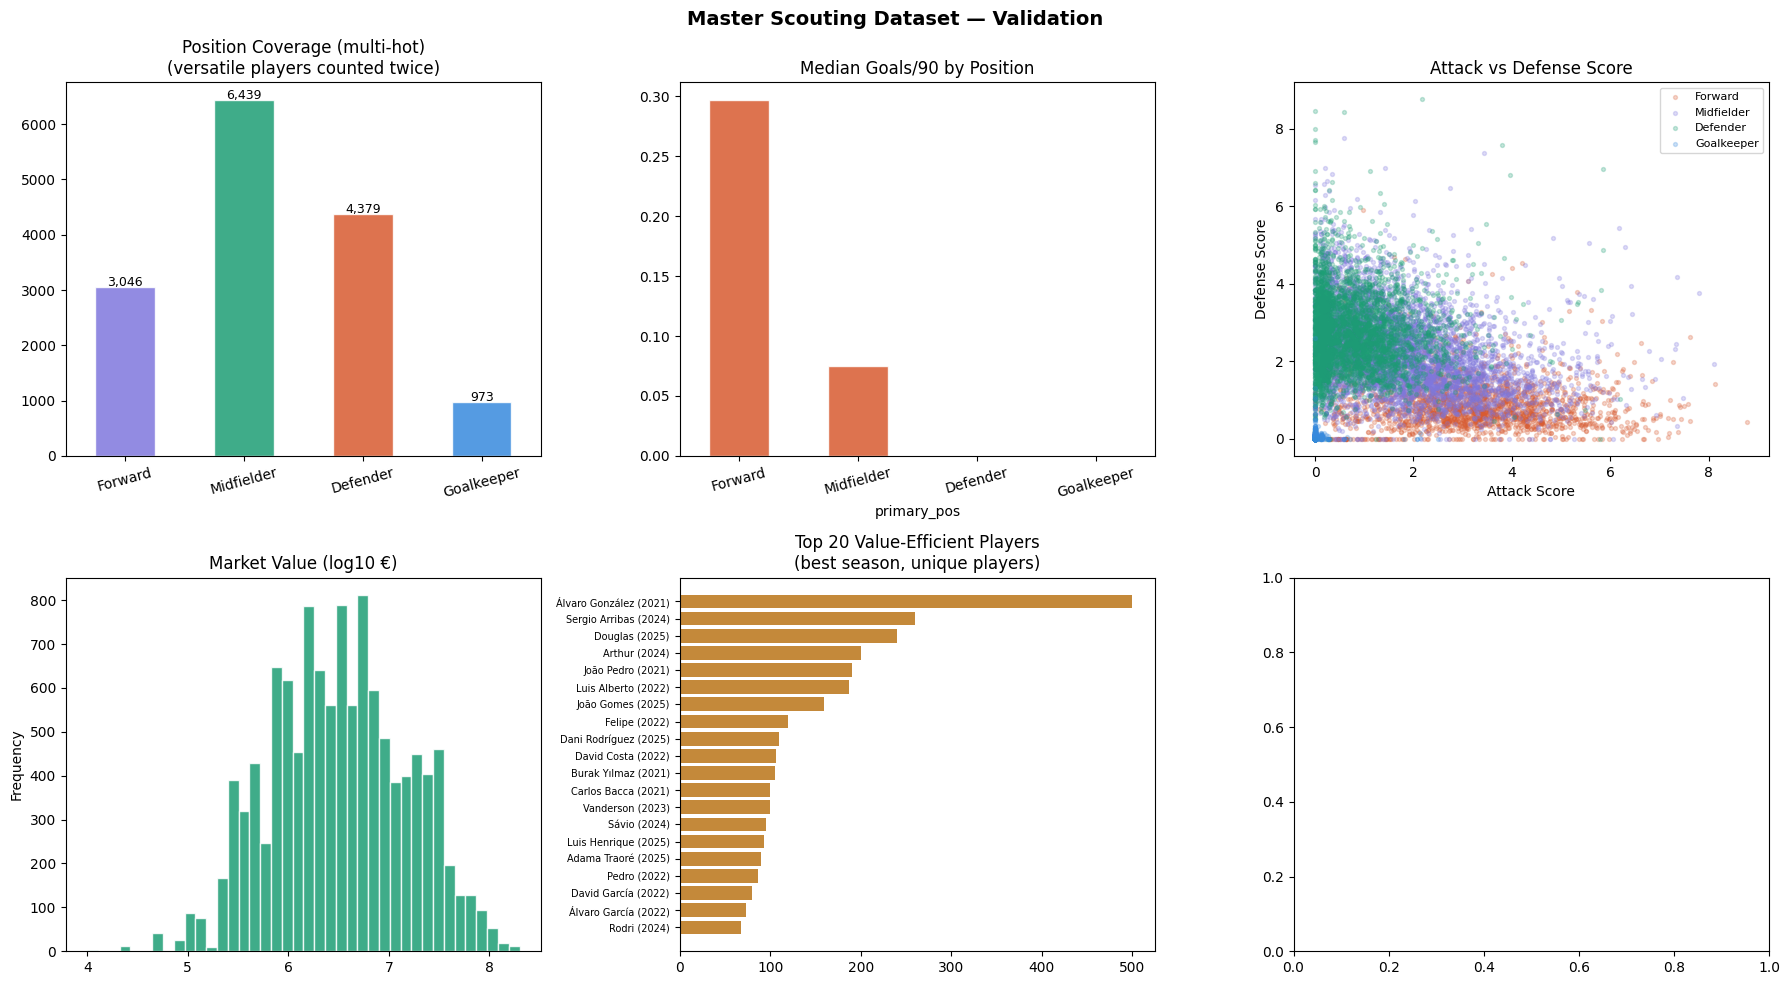

💾 Saved → reports/05_master_validation.png


In [64]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Master Scouting Dataset — Validation', fontsize=14, fontweight='bold')

# Position distribution (multi-hot)
ax = axes[0,0]
pos_dist = pd.Series({'Forward':df_out['pos_FW'].sum(),'Midfielder':df_out['pos_MF'].sum(),
                      'Defender':df_out['pos_DF'].sum(),'Goalkeeper':df_out['pos_GK'].sum()})
pos_dist.plot.bar(ax=ax, color=COLORS, alpha=0.85, edgecolor='white')
ax.set_title('Position Coverage (multi-hot)\n(versatile players counted twice)')
ax.tick_params(axis='x', rotation=15)
for bar in ax.patches:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+20,
            f'{int(bar.get_height()):,}', ha='center', fontsize=9)

# Goals p90 by position
ax = axes[0,1]
if 'goals_p90' in df_out.columns and 'primary_pos' in df_out.columns:
    df_out.groupby('primary_pos')['goals_p90'].median().sort_values(ascending=False).plot.bar(
        ax=ax, color=COLORS[2], alpha=0.85, edgecolor='white')
    ax.set_title('Median Goals/90 by Position'); ax.tick_params(axis='x', rotation=15)

# Attack vs Defense score
ax = axes[0,2]
if 'attack_score' in df_out.columns and 'defense_score' in df_out.columns:
    for pos, color in [('Forward',COLORS[2]),('Midfielder',COLORS[0]),
                        ('Defender',COLORS[1]),('Goalkeeper',COLORS[3])]:
        mask = df_out['primary_pos'] == pos
        ax.scatter(df_out[mask]['attack_score'], df_out[mask]['defense_score'],
                   alpha=0.25, s=8, color=color, label=pos)
    ax.set_title('Attack vs Defense Score'); ax.legend(fontsize=8)
    ax.set_xlabel('Attack Score'); ax.set_ylabel('Defense Score')

# Market value distribution
ax = axes[1,0]
if 'market_value_eur' in df_out.columns:
    vals = pd.to_numeric(df_out['market_value_eur'], errors='coerce').dropna()
    vals = vals[vals > 0]
    np.log10(vals).plot.hist(bins=40, ax=ax, color=COLORS[1], alpha=0.85, edgecolor='white')
    ax.set_title('Market Value (log10 €)')

# Value efficiency
ax = axes[1,1]
if 'value_efficiency' in df_out.columns:
    # Keep only best season per player to avoid duplicates
    best_per_player = (
        df_out[df_out['value_efficiency'].notna()]
        .sort_values('value_efficiency', ascending=False)
        .drop_duplicates('Player', keep='first')   # ← THIS LINE
        .head(20)
    )
    ax.barh(range(len(best_per_player)),
            best_per_player['value_efficiency'].values,
            color=COLORS[4], alpha=0.85)
    ax.set_yticks(range(len(best_per_player)))
    ax.set_yticklabels(
        [f"{row['Player']} ({row['season'][-4:]})"
         for _, row in best_per_player.iterrows()],
        fontsize=7
    )
    ax.set_title('Top 20 Value-Efficient Players\n(best season, unique players)')
    ax.invert_yaxis()

# Injury risk
ax = axes[1,2]
if 'injury_risk_label' in df_out.columns:
    df_out['injury_risk_label'].value_counts().plot.bar(
        ax=ax, color=COLORS[5], alpha=0.85, edgecolor='white')
    ax.set_title('Injury Risk Distribution'); ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig(REPORTS / '05_master_validation.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/05_master_validation.png')

## 🖨️ 16 — Summary Print for Claude

In [65]:
num_features = df_out.select_dtypes(include=np.number).columns.tolist()

summary = {
    'master_dataset': {
        'rows': len(df_out),
        'total_columns': len(df_out.columns),
        'numeric_features': len(num_features),
        'all_columns': list(df_out.columns),
        'numeric_columns': num_features,
    },
    'coverage': {
        'unique_players':  int(df_out['Player'].nunique()),
        'seasons':         sorted(df_out['season'].unique().tolist()),
        'leagues':         sorted(df_out['league'].unique().tolist()),
        'positions_multi': {
            'pos_FW': int(df_out['pos_FW'].sum()),
            'pos_MF': int(df_out['pos_MF'].sum()),
            'pos_DF': int(df_out['pos_DF'].sum()),
            'pos_GK': int(df_out['pos_GK'].sum()),
            'versatile_players': int(df_out['is_versatile'].sum()),
        },
    },
    'data_quality': {
        c: f"{df_out[c].isna().mean()*100:.1f}%"
        for c in ['goals_p90','assists_p90','attack_score','defense_score',
                  'market_value_eur','weekly_eur','injury_risk_score',
                  'value_efficiency','tackles_won_p90']
        if c in df_out.columns
    },
    'feature_groups': {k: [c for c in v if c in df_out.columns]
                       for k, v in FINAL_FEATURES.items()},
    'correlation_analysis': {
        'dropped_redundant': list(REDUNDANT_COLS.keys()),
        'reason_summary': 'Dropped 15 columns: 6 perfectly derived (r=1.0), 5 FBref pre-computed per-90, 4 high-correlation duplicates',
    },
    'position_encoding': {
        'method': 'multi-hot (not single label)',
        'columns': ['pos_FW','pos_MF','pos_DF','pos_GK','primary_pos','is_versatile'],
        'versatile_pct': f"{df_out['is_versatile'].mean()*100:.1f}%",
        'why': 'For the recommendation engine: pos_MF=1 finds all midfielders including MF,FW versatile players',
    },
    'ml_ready': {
        'model_1_knn_similarity': f'READY — {len(num_features)} numeric features for cosine similarity',
        'model_2_xgboost':        'READY — all features + labels available',
        'model_3_kmeans':         'READY — subset by primary_pos, cluster on per-90 stats',
        'recommendation_engine':  'READY — filter by pos_FW/MF/DF/GK (multi-hot), rank by overall_score + value_efficiency',
    },
    'next_notebook':  'notebook 04 — Model 1: KNN Similarity Engine',
}

print('='*65)
print('  NB03 COMPLETE — SUMMARY FOR CLAUDE')
print('='*65)
print(json.dumps(summary, indent=2, default=str))

with open(PROCESSED / 'nb03_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=str)

print(f"""
{'='*65}
  MASTER DATASET READY:
  Rows:              {summary['master_dataset']['rows']:,}
  Numeric features:  {summary['master_dataset']['numeric_features']}
  Unique players:    {summary['coverage']['unique_players']:,}
  Versatile players: {summary['coverage']['positions_multi']['versatile_players']:,}
  Dropped redundant: {len(summary['correlation_analysis']['dropped_redundant'])} columns
  → NEXT: notebook 04 — KNN Similarity Model
{'='*65}
""")

  NB03 COMPLETE — SUMMARY FOR CLAUDE
{
  "master_dataset": {
    "rows": 11965,
    "total_columns": 64,
    "numeric_features": 53,
    "all_columns": [
      "Player",
      "name_norm",
      "Nation",
      "Age",
      "primary_pos",
      "pos_FW",
      "pos_MF",
      "pos_DF",
      "pos_GK",
      "is_versatile",
      "Squad",
      "league",
      "season",
      "country_of_citizenship",
      "sub_position",
      "foot",
      "height_in_cm",
      "games_played",
      "starts",
      "minutes_played",
      "availability_pct",
      "goals",
      "assists",
      "penalties_scored",
      "goals_p90",
      "assists_p90",
      "g_a_p90",
      "shots_p90",
      "shot_accuracy_pct",
      "conversion_rate",
      "finishing_quality",
      "tackles_won",
      "interceptions",
      "tackles_won_p90",
      "interceptions_p90",
      "def_actions_p90",
      "yellow_cards",
      "red_cards",
      "yellow_p90",
      "red_p90",
      "market_value_eur",
      "peak_